# Synthetische Letalität bei Mensch, Ratte und *E. coli*

**Leitfragen dieser Analyse**

1. Wie stelle ich mit unseren BioGRID-Daten fest, **ob und welche Gene** einer Spezies synthetisch letal sind?
2. Wie sind diese Gene (und beim Menschen die **Zelllinien**, in denen gemessen wurde) **pro Spezies aufgebaut bzw. verteilt**?
3. Wie lassen sich die Gene von Ratte und *E. coli* **auf den Menschen abbilden**, und ist synthetische Letalität **übertragbar**? Wenn ja, wie?

> **Hinweis:** Diese Analyse nutzt bewusst **nur die Daten, die schon im Repo liegen** (`./install.sh`).
> Für eine saubere Abbildung auf den Menschen fehlen noch Orthologie-Daten, siehe Abschnitt 9 (*Offene Tasks*).

---

## 0. Kurz erklärt: Was ist synthetische Letalität?

Eine Zelle hat für viele lebenswichtige Aufgaben **zwei Wege** (wie zwei Brücken über einen Fluss).

| Gen A | Gen B | Zelle |
|---|---|---|
| funktioniert | funktioniert | lebt |
| **ausgeschaltet** | funktioniert | lebt (Brücke B reicht) |
| funktioniert | **ausgeschaltet** | lebt (Brücke A reicht) |
| **ausgeschaltet** | **ausgeschaltet** | **stirbt** |

Wenn das Ausschalten **jedes einzelnen** Gens harmlos ist, das Ausschalten **beider zusammen** aber tödlich, nennt man das Genpaar
**synthetisch letal (SL)**.

**Warum ist das spannend?** In der Krebsforschung: Hat ein Tumor Gen A schon durch eine Mutation verloren, tötet ein Medikament gegen Gen B
nur die Tumorzellen. Gesunde Zellen haben Gen A noch und überleben (Beispiel aus der Klinik: *BRCA*-Mutation + PARP-Hemmer).

**Wichtig für das Verständnis:**
* SL ist eine Eigenschaft eines **Genpaares**, nicht einer einzelnen Zelle oder eines einzelnen Gens.
* Gemessen wird es aber **in Zellen**: bei Bakterien/Hefe im ganzen Organismus (Einzeller), beim Menschen in **Zelllinien** (meist Krebszellen im Labor).
  Deshalb schauen wir uns beim Menschen zusätzlich an, *in welchen Zelllinien* SL gefunden wurde.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 80)

# Projekt-Ordner finden (Notebook kann im Repo-Root oder in analysis/ gestartet werden)
ROOT = Path.cwd() if (Path.cwd() / "install.sh").exists() else Path.cwd().parent
SL_FILE = sorted((ROOT / "BIOGRID-SYSTEM-LATEST.tab3").glob("BIOGRID-SYSTEM-Synthetic_Lethality-*.tab3.txt.csv"))[-1]
ORG_DIR = ROOT / "BIOGRID-ORGANISM-4.4.225.mitab"
OUT = ROOT / "analysis" / "results"
OUT.mkdir(parents=True, exist_ok=True)

# Unsere Spezies und ihre NCBI-Taxonomie-IDs (E. coli K-12 kommt in BioGRID als 4 Stämme vor)
SPECIES = {
    "Mensch": {9606},
    "Ratte": {10116},
    "E. coli K-12": {83333, 511145, 316407, 595496},
}
ECOLI_STRAINS = {83333: "K-12", 511145: "K-12 MG1655", 316407: "K-12 W3110", 595496: "K-12 MC4100/BW2952"}

# Farben: eine feste Farbe pro Spezies (Farbe folgt immer der Spezies)
COLOR = {"Mensch": "#2a78d6", "E. coli K-12": "#eb6834", "Ratte": "#1baf7a"}
BLUE, GRAY = "#2a78d6", "#a3a29c"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e",
    "axes.grid": True, "axes.grid.axis": "x", "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#0b0b0b",
})

def de(n, digits=0):
    # Zahl im deutschen Format: 12.345 bzw. 12,3
    s = f"{n:,.{digits}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def barh(values, title, xlabel="", color=BLUE, colors=None, log=False, pct=False, width=7.5):
    # Horizontales Balkendiagramm, größter Wert oben, Wert direkt am Balken
    values = values.iloc[::-1]
    cols = list(colors)[::-1] if colors is not None else color
    fig, ax = plt.subplots(figsize=(width, 0.34 * len(values) + 1.1))
    bars = ax.barh([str(i) for i in values.index], values.values, color=cols, height=0.62)
    if log:
        ax.set_xscale("log")
    vmax = values.max()
    for b, v in zip(bars, values.values):
        label = (de(v, 1) + " %") if pct else de(v)
        x = b.get_width() * 1.12 if log else b.get_width() + vmax * 0.01
        ax.text(x, b.get_y() + b.get_height() / 2, label, va="center", fontsize=9, color="#52514e")
    if pct:
        ax.set_xlim(0, 100)
    elif not log:
        ax.set_xlim(0, vmax * 1.15)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.tick_params(axis="y", length=0)
    plt.tight_layout()
    plt.show()

def pair_key(a, b):
    # Ungeordnetes Genpaar: A–B und B–A sind dasselbe Paar
    a, b = a.astype(str), b.astype(str)
    return np.where(a <= b, a + " – " + b, b + " – " + a)

## 1. Welche Datensätze haben wir?

Alle Daten stammen aus **BioGRID** (frei zugängliche Datenbank für Gen- und Protein-Interaktionen) und werden mit `./install.sh` geladen.

| Datei | Version | Format | Inhalt |
|---|---|---|---|
| `BIOGRID-SYSTEM-Synthetic_Lethality-*.tab3.txt.csv` | 5.0.x (neu) | TAB 3.0 | **Nur SL-Interaktionen**, aber für *alle* Organismen in BioGRID |
| `BIOGRID-ORGANISM-<Spezies>-4.4.225.mitab.txt.csv` | 4.4.225 (Aug. 2023) | PSI-MITAB 2.5 | **Alle Interaktionsarten** (physikalisch + genetisch), aber nur für *eine* Spezies |

Eine Zeile = **eine beobachtete Interaktion zwischen zwei Genen (Interactor A und B)** in einer bestimmten Publikation.
Dasselbe Genpaar kann also mehrfach vorkommen (mehrere Studien oder Versuchsbedingungen).

> ⚠️ Die beiden Dateien haben **unterschiedliche BioGRID-Versionen** (SL-Datei ist ca. 2 Jahre neuer). Zahlen zwischen den Dateien können sich deshalb leicht unterscheiden.

In [2]:
MITAB_COLS = {
    "#ID Interactor A": "idA", "ID Interactor B": "idB",
    "Alt IDs Interactor A": "altA", "Alt IDs Interactor B": "altB",
    "Interaction Detection Method": "method", "Publication 1st Author": "author",
    "Taxid Interactor A": "taxA", "Taxid Interactor B": "taxB",
    "Interaction Types": "itype", "Confidence Values": "conf",
}

def load_mitab(path, cols=None):
    # MITAB-Datei laden und die wichtigsten Felder lesbar machen
    usecols = cols or list(MITAB_COLS)
    df = pd.read_csv(path, sep="\t", dtype=str, usecols=usecols).rename(columns=MITAB_COLS)
    for s in "AB":
        # Gensymbol = erster "entrez gene/locuslink:"-Eintrag in den Alt IDs
        df["sym" + s] = df["alt" + s].str.extract(r"entrez gene/locuslink:([^|]+)")[0]
        df["tax" + s] = df["tax" + s].str.removeprefix("taxid:").astype(int)
    # 'psi-mi:"MI:2373"("negative genetic interaction (sensu biogrid)")' -> 'negative genetic interaction'
    df["type"] = (df["itype"].str.replace(r'^psi-mi:"MI:\d+"\(', "", regex=True)
                  .str.replace(r"\)$", "", regex=True).str.strip('"')
                  .str.replace(" (sensu biogrid)", "", regex=False))
    if "method" in df:
        df["genetisch"] = df["method"].str.contains("MI:0254")  # MI:0254 = genetic interference
    if "conf" in df:
        df["score"] = df["conf"].str.extract(r"score:(-?[\d.]+)")[0].astype(float)
    return df

def within(df, taxa):
    # nur Interaktionen, bei denen BEIDE Gene aus der Spezies stammen
    return df[df.taxA.isin(taxa) & df.taxB.isin(taxa)]

# SL-Datei (TAB 3.0)
sl_all = pd.read_csv(SL_FILE, sep="\t", dtype=str)
sl_all = sl_all.rename(columns={
    "Official Symbol Interactor A": "symA", "Official Symbol Interactor B": "symB",
    "Organism ID Interactor A": "taxA", "Organism ID Interactor B": "taxB",
    "Organism Name Interactor A": "orgA", "Organism Name Interactor B": "orgB",
})
sl_all["taxA"] = sl_all.taxA.astype(int)
sl_all["taxB"] = sl_all.taxB.astype(int)

# Organismus-Dateien (MITAB)
rat = load_mitab(ORG_DIR / "BIOGRID-ORGANISM-Rattus_norvegicus-4.4.225.mitab.txt.csv")
ecoli = pd.concat([load_mitab(p) for p in sorted(ORG_DIR.glob("BIOGRID-ORGANISM-Escherichia_coli_K12*.mitab.txt.csv"))],
                  ignore_index=True)
# Mensch: ~1 GB, daher nur die nötigen Spalten
human = load_mitab(ORG_DIR / "BIOGRID-ORGANISM-Homo_sapiens-4.4.225.mitab.txt.csv",
                   cols=["Alt IDs Interactor A", "Alt IDs Interactor B", "Taxid Interactor A",
                         "Taxid Interactor B", "Interaction Types", "Interaction Detection Method"])

files = pd.DataFrame([
    ("SL-Datei (alle Organismen)", SL_FILE.name, len(sl_all)),
    ("Mensch", "Homo_sapiens", len(human)),
    ("Ratte", "Rattus_norvegicus", len(rat)),
    ("E. coli K-12 (4 Stämme zusammen)", "Escherichia_coli_K12*", len(ecoli)),
], columns=["Datensatz", "Datei", "Zeilen"]).set_index("Datensatz")
files["Zeilen"] = files["Zeilen"].map(de)
files

,Datei,Zeilen
Datensatz,,
SL-Datei (alle Organismen),BIOGRID-SYSTEM-Synthetic_Lethality-5.0.263.tab3.txt.csv,21.771
Mensch,Homo_sapiens,1.170.120
Ratte,Rattus_norvegicus,10.173
E. coli K-12 (4 Stämme zusammen),Escherichia_coli_K12*,201.645


## 2. Wie erkenne ich synthetische Letalität in den Daten?

Es gibt **zwei Stellen**, an denen SL steht:

| Datei | Spalte | Wert, nach dem gefiltert wird |
|---|---|---|
| SL-Datei (TAB 3.0) | `Experimental System` | `Synthetic Lethality` (alle Zeilen der Datei) |
| SL-Datei (TAB 3.0) | `Organism ID Interactor A` / `B` | Taxonomie-ID der Spezies (Mensch 9606, Ratte 10116, *E. coli* K-12 83333 / 511145 / 316407 / 595496) |
| Organismus-Datei (MITAB) | `Interaction Types` | `psi-mi:"MI:2370"("synthetic lethality (sensu biogrid)")` |

Zusätzlich gibt es eine **„weichere“ Variante**: die **negative genetische Interaktion** (`MI:2373`).
Sie bedeutet: Die Doppelmutante wächst **deutlich schlechter als erwartet**. Das reicht von „krank“ bis „tot“.
Ein **Score** sagt, wie stark der Effekt ist (je negativer, desto schlimmer). Sehr stark negative Werte sind **SL-Kandidaten**.

Als SQL formuliert (z.B. wenn die CSV in eine Tabelle `sl` importiert wird):

```sql
-- Alle SL-Genpaare innerhalb des Menschen
SELECT "Official Symbol Interactor A", "Official Symbol Interactor B", "Author", "Qualifications"
FROM sl
WHERE "Experimental System" = 'Synthetic Lethality'
  AND "Organism ID Interactor A" = 9606
  AND "Organism ID Interactor B" = 9606;
```

**Wichtig:** Nur Zeilen, bei denen **beide** Gene aus derselben Spezies stammen, sagen etwas über SL *in dieser Spezies* aus.
Zeilen mit zwei verschiedenen Spezies sind Spezialexperimente (z.B. ein menschliches Gen in Hefe eingebaut).

Erst einmal der Blick auf die **gesamte SL-Datei**: Welche Organismen kommen vor?

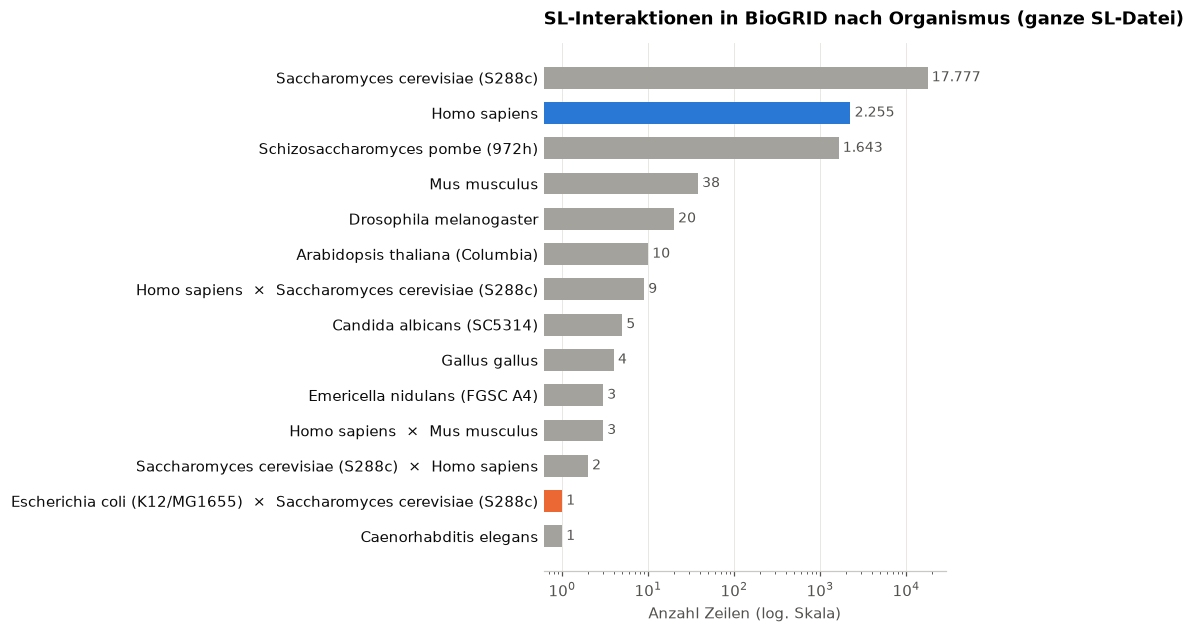

Ratte in der SL-Datei: 0 Zeilen
E. coli in der SL-Datei: 1 Zeile(n)


In [3]:
sl_all["Organismen"] = np.where(sl_all.orgA == sl_all.orgB, sl_all.orgA, sl_all.orgA + "  ×  " + sl_all.orgB)
org_counts = sl_all["Organismen"].value_counts()
mark = lambda name: ("Mensch" if name == "Homo sapiens" else
                     "E. coli K-12" if "Escherichia" in name else
                     "Ratte" if "Rattus" in name else None)
colors = [COLOR.get(mark(n), GRAY) for n in org_counts.index]
barh(org_counts, "SL-Interaktionen in BioGRID nach Organismus (ganze SL-Datei)",
     "Anzahl Zeilen (log. Skala)", colors=colors, log=True, width=9)
print("Ratte in der SL-Datei:", int((sl_all.taxA.isin(SPECIES['Ratte']) | sl_all.taxB.isin(SPECIES['Ratte'])).sum()), "Zeilen")
print("E. coli in der SL-Datei:", int((sl_all.taxA.isin(SPECIES['E. coli K-12']) | sl_all.taxB.isin(SPECIES['E. coli K-12'])).sum()), "Zeile(n)")

**Erste große Erkenntnis:** Synthetische Letalität ist in BioGRID fast nur für **Hefe** (*S. cerevisiae*, *S. pombe*) und den **Menschen** erfasst.
Für die **Ratte gibt es keinen einzigen Eintrag**, für *E. coli* genau **einen**, und der ist ein Experiment zwischen *E. coli* und Hefe.

Deshalb schauen wir als Nächstes in die **Organismus-Dateien**: Gibt es dort andere genetische Interaktionen, die man nutzen kann?

## 3. Überblick pro Spezies

Für jede Spezies zählen wir nur Interaktionen **innerhalb** der Spezies (beide Gene aus derselben Spezies).

In [4]:
human_sl = within(sl_all, SPECIES["Mensch"]).copy()
human_sl["pair"] = pair_key(human_sl.symA, human_sl.symB)

rat_in = within(rat, SPECIES["Ratte"])
eco_in = within(ecoli, SPECIES["E. coli K-12"])
hum_in = within(human, SPECIES["Mensch"])

def overview(name, df, sl_rows=None):
    gen = df[df.genetisch]
    sl = sl_rows if sl_rows is not None else df[df.type == "synthetic lethality"]
    neg = df[df.type == "negative genetic interaction"]
    return {
        "Spezies": name,
        "Interaktionen gesamt": len(df),
        "davon physikalisch": int((~df.genetisch).sum()),
        "davon genetisch": len(gen),
        "SL explizit (MI:2370)": len(sl),
        "negativ genetisch (MI:2373)": len(neg),
        "Gene mit SL": pd.concat([sl.symA, sl.symB]).nunique() if len(sl) else 0,
    }

ov = pd.DataFrame([
    overview("Mensch", hum_in, sl_rows=human_sl),   # SL aus der neueren SL-Datei
    overview("Ratte", rat_in),
    overview("E. coli K-12", eco_in),
]).set_index("Spezies")
ov.to_csv(OUT / "spezies_ueberblick.csv")
ov.map(de)

,Interaktionen gesamt,davon physikalisch,davon genetisch,SL explizit (MI:2370),negativ genetisch (MI:2373),Gene mit SL
Spezies,,,,,,
Mensch,1.090.297,1.072.725,17.572,2.255,9.615,1.954
Ratte,6.857,6.851,6,0,0,0
E. coli K-12,201.573,15.076,186.497,0,97.586,0


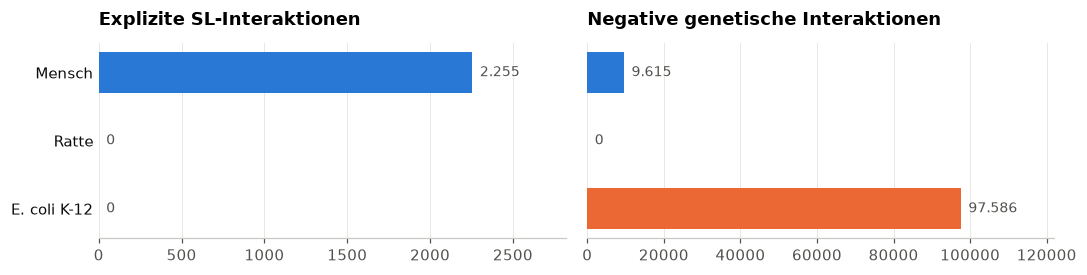

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True)
for ax, col, title in [(axes[0], "SL explizit (MI:2370)", "Explizite SL-Interaktionen"),
                       (axes[1], "negativ genetisch (MI:2373)", "Negative genetische Interaktionen")]:
    vals = ov[col].iloc[::-1]
    bars = ax.barh(vals.index, vals.values, color=[COLOR[s] for s in vals.index], height=0.6)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_width() + max(vals.max(), 1) * 0.02, b.get_y() + b.get_height() / 2, de(v), va="center", fontsize=9, color="#52514e")
    ax.set_xlim(0, max(vals.max(), 1) * 1.25)
    ax.set_title(title)
    ax.tick_params(axis="y", length=0)
plt.tight_layout(); plt.show()

**Was die Tabelle zeigt:**

| Spezies | Gibt es SL-Daten? | Was wir nutzen können |
|---|---|---|
| **Mensch** | ✅ ja, ~2.250 explizite SL-Interaktionen | direkt die SL-Paare |
| **E. coli K-12** | ❌ keine expliziten SL innerhalb *E. coli*, aber ~97.600 **negative genetische Interaktionen** mit Score | starke negative Interaktionen als **SL-Kandidaten** |
| **Ratte** | ❌ nein, fast nur physikalische Interaktionen (Proteine binden aneinander) | SL **nicht bestimmbar**; nur Hypothesen vom Menschen ableiten |

*(Die Mensch-Organismusdatei 4.4.225 enthält ebenfalls SL-Einträge; wir verwenden aber die neuere SL-Datei, weil sie mehr Details wie die Zelllinie enthält.)*

In [6]:
print("Explizite SL in der älteren Mensch-Organismusdatei (4.4.225):", de((hum_in.type == "synthetic lethality").sum()))
print("Explizite SL in der neueren SL-Datei:", de(len(human_sl)))

Explizite SL in der älteren Mensch-Organismusdatei (4.4.225): 2.151
Explizite SL in der neueren SL-Datei: 2.255


## 4. Mensch: Wie sind die SL-Gene aufgebaut und verteilt?

### 4.1 Gene und Genpaare


| Kennzahl | Wert |
|---|---|
| SL-Zeilen (Mensch × Mensch) | **2.255** |
| verschiedene Genpaare | **2.219** |
| verschiedene Gene | **1.954** |
| Paare, die mehr als einmal berichtet wurden | 36 |
| Studien (Publikationen) | 34 |


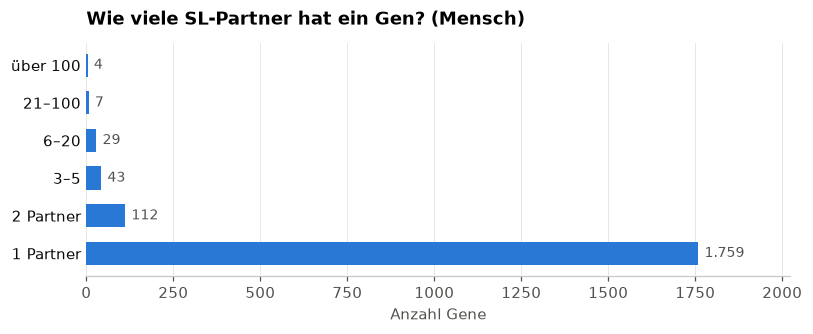

In [7]:
h_genes = pd.concat([human_sl.symA, human_sl.symB])
partners = (pd.concat([human_sl[["symA", "symB"]].set_axis(["g", "p"], axis=1),
                       human_sl[["symB", "symA"]].set_axis(["g", "p"], axis=1)])
            .drop_duplicates().groupby("g")["p"].nunique().sort_values(ascending=False))
pair_n = human_sl.groupby("pair").size()

display(Markdown(f'''
| Kennzahl | Wert |
|---|---|
| SL-Zeilen (Mensch × Mensch) | **{de(len(human_sl))}** |
| verschiedene Genpaare | **{de(human_sl.pair.nunique())}** |
| verschiedene Gene | **{de(h_genes.nunique())}** |
| Paare, die mehr als einmal berichtet wurden | {de((pair_n > 1).sum())} |
| Studien (Publikationen) | {de(human_sl.Author.nunique())} |
'''))

bins = pd.cut(partners, [0, 1, 2, 5, 20, 100, 10_000],
              labels=["1 Partner", "2 Partner", "3–5", "6–20", "21–100", "über 100"])
barh(bins.value_counts().sort_index().iloc[::-1],
     "Wie viele SL-Partner hat ein Gen? (Mensch)", "Anzahl Gene")

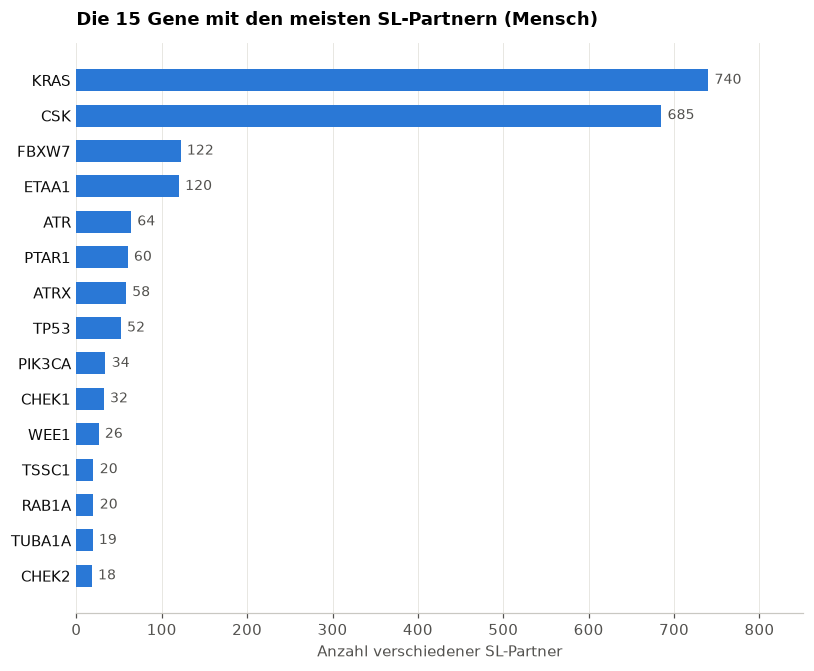

In [8]:
top = partners.head(15)
barh(top, "Die 15 Gene mit den meisten SL-Partnern (Mensch)", "Anzahl verschiedener SL-Partner")
partners.rename("SL-Partner").to_csv(OUT / "mensch_sl_gene.csv")

**So liest man das:**
* Die **allermeisten Gene haben nur 1 SL-Partner**. Das Netz besteht aus wenigen **„Knoten“-Genen** (Hubs) mit sehr vielen Partnern.
* **KRAS** (Onkogen, in vielen Tumoren mutiert), **CSK**, **FBXW7**, **ATR**, **TP53**: Das sind Gene, die gezielt als „Köder“ (*Bait*) untersucht wurden.
  Forschende suchen *„Was ist SL mit mutiertem KRAS?“* und testen dafür tausende Partner.
* Das heißt: Die Verteilung spiegelt **auch wider, wonach geforscht wurde**, nicht nur die Biologie. Ein Gen ohne SL-Eintrag ist nicht „sicher nicht SL“, sondern oft einfach **nie getestet**.

### 4.2 Methoden und Studien

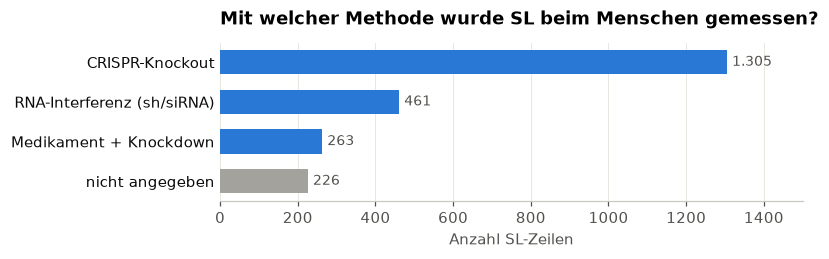

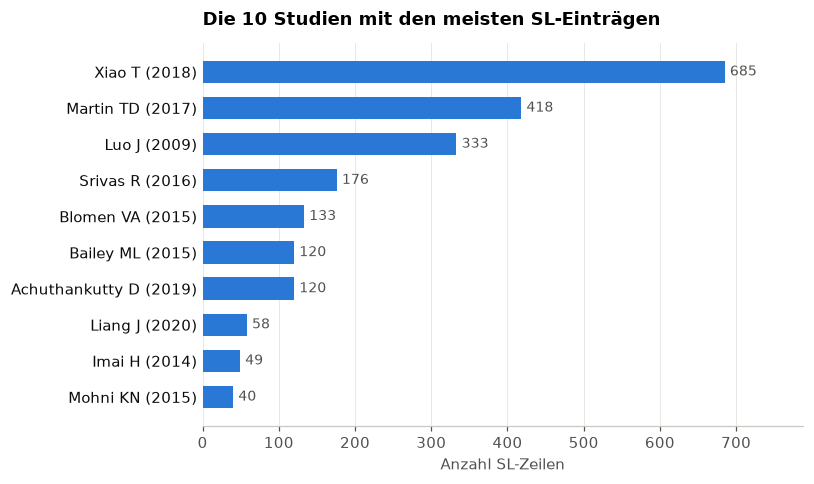

Anteil High-Throughput (große Screens): 83,6 %


In [9]:
def method_of(q):
    q = str(q).lower()
    if any(k in q for k in ["chemo-genetic", "drug", "inhibit", "olaparib"]):
        return "Medikament + Knockdown"
    if "crispr" in q:
        return "CRISPR-Knockout"
    if any(k in q for k in ["shrna", "sirna", "rnai"]):
        return "RNA-Interferenz (sh/siRNA)"
    return "nicht angegeben"

human_sl["Methode"] = human_sl.Qualifications.map(method_of)
m = human_sl.Methode.value_counts()
barh(m, "Mit welcher Methode wurde SL beim Menschen gemessen?", "Anzahl SL-Zeilen",
     colors=[GRAY if i == "nicht angegeben" else BLUE for i in m.index])

barh(human_sl.Author.value_counts().head(10), "Die 10 Studien mit den meisten SL-Einträgen", "Anzahl SL-Zeilen")
print("Anteil High-Throughput (große Screens):",
      de(human_sl.Throughput.str.contains("High").mean() * 100, 1), "%")

* **CRISPR** (Gen dauerhaft ausschalten) und **RNA-Interferenz** (Gen vorübergehend herunterregeln) sind die Hauptmethoden.
* „Medikament + Knockdown“: Ein Gen wird per Medikament gehemmt, das zweite per siRNA heruntergeregelt (*chemo-genetisch*).
* Über 80 % stammen aus **großen Screens** (High Throughput), wenige Studien liefern den Großteil der Daten.

### 4.3 In welchen Zelllinien wurde gemessen?

Die Zelllinie steht nicht in einer eigenen Spalte, sondern als Freitext in `Qualifications`
(z.B. `Cell Line: T47D` oder `...synthetic lethality with K-Ras mutant in DLD1 cells`). Wir suchen bekannte Namen heraus.

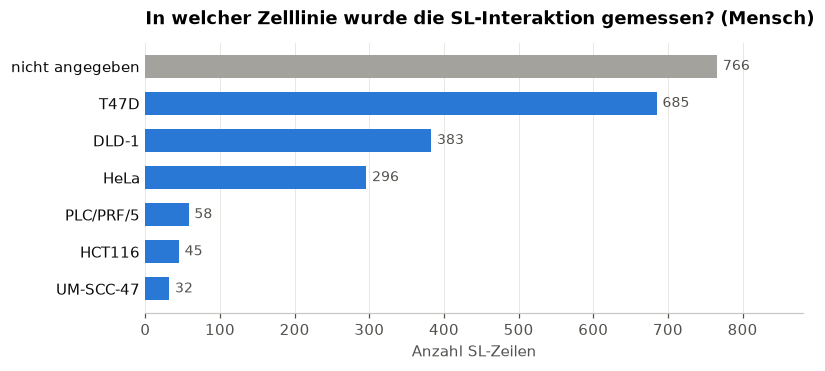

,Gewebe / Herkunft,SL-Zeilen,Genpaare,Gene,Köder-Gen(e),Studien
Zelllinie,,,,,,
nicht angegeben,–,766,756,697,KRAS,28
T47D,Brustkrebs,685,685,686,CSK,1
DLD-1,Darmkrebs (KRAS-mutiert),383,383,384,KRAS,1
HeLa,Gebärmutterhalskrebs,296,294,186,ETAA1,2
PLC/PRF/5,Leberkrebs,58,58,59,ATRX,1
HCT116,Darmkrebs (KRAS-mutiert),45,45,46,KRAS,1
UM-SCC-47,Kopf-Hals-Krebs (HPV16+),32,32,33,PIK3CA,1


In [10]:
CELL_LINES = [  # (Suchmuster, Name, Gewebe/Herkunft)
    (r"T47D",         "T47D",      "Brustkrebs"),
    (r"HELA",         "HeLa",      "Gebärmutterhalskrebs"),
    (r"DLD-?1",       "DLD-1",     "Darmkrebs (KRAS-mutiert)"),
    (r"HCT-?116",     "HCT116",    "Darmkrebs (KRAS-mutiert)"),
    (r"PLC-PRF-5",    "PLC/PRF/5", "Leberkrebs"),
    (r"UM-SCC-47",    "UM-SCC-47", "Kopf-Hals-Krebs (HPV16+)"),
]
def cell_lines_of(q):
    found = [name for pat, name, _ in CELL_LINES if re.search(pat, str(q), flags=re.I)]
    return found or ["nicht angegeben"]

human_sl["Zelllinie"] = human_sl.Qualifications.map(cell_lines_of)
cl = human_sl.explode("Zelllinie")
cl_counts = cl.Zelllinie.value_counts()
barh(cl_counts, "In welcher Zelllinie wurde die SL-Interaktion gemessen? (Mensch)", "Anzahl SL-Zeilen",
     colors=[GRAY if i == "nicht angegeben" else BLUE for i in cl_counts.index])

tissue = {name: t for _, name, t in CELL_LINES}
cl_tab = (cl.groupby("Zelllinie").agg(**{"SL-Zeilen": ("pair", "size"), "Genpaare": ("pair", "nunique"),
                                        "Studien": ("Author", "nunique")})
          .sort_values("SL-Zeilen", ascending=False))
cl_tab.insert(2, "Gene", cl.groupby("Zelllinie").apply(lambda g: pd.concat([g.symA, g.symB]).nunique()).reindex(cl_tab.index))
cl_tab.insert(3, "Köder-Gen(e)", cl.groupby("Zelllinie").apply(
    lambda g: ", ".join(pd.concat([g.symA, g.symB]).value_counts().loc[lambda v: v >= 0.3 * len(g)].index[:3]) or "–"
).reindex(cl_tab.index))
cl_tab.insert(0, "Gewebe / Herkunft", [tissue.get(i, "–") for i in cl_tab.index])
cl_tab.to_csv(OUT / "mensch_zelllinien.csv")
cl_tab

**Erkenntnisse zu den Zelllinien:**
* Bei rund **einem Drittel** der Einträge ist die Zelllinie **nicht als Text angegeben** (steht nur in der Original-Publikation).
* **Alle** benannten Zelllinien sind **Krebszellen**. SL beim Menschen ist also fast immer **„SL in einer bestimmten Krebszelle“**, nicht SL im gesunden Gewebe.
* Fast jede Zelllinie stammt aus **einer einzigen Studie** mit **einem Köder-Gen**: T47D = 685 Partner von *CSK*, DLD-1/HCT116 = Partner von mutiertem *KRAS*.
  Pro Zelllinie wurde also meist *eine* Frage gestellt („Was ist SL mit Gen X in dieser Zelle?“).

### 4.4 Wie stabil ist SL beim Menschen? (Kontextabhängigkeit)

Wenn ein Genpaar *wirklich universell* SL wäre, müsste es in **mehreren Studien / Zelllinien** auftauchen. Prüfen wir das:

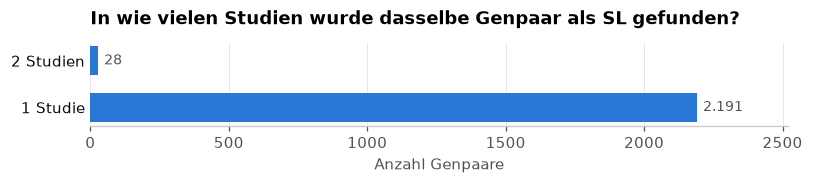

Nur 1,3 % der Paare wurden von mehr als einer Studie bestätigt.
Nur 10 Paare sind in mehr als einer (benannten) Zelllinie belegt.


,Studien,Zelllinien
pair,,
GSPT1 – KRAS,2,1
CDCA8 – KRAS,2,1
ANAPC4 – KRAS,2,1
EPRS – KRAS,2,1
KRAS – THOC1,2,1
KRAS – RQCD1,2,1
KRAS – SNW1,2,1
KRAS – PSMB6,2,1
KRAS – TBCD,2,1


In [11]:
per_pair = human_sl.groupby("pair").agg(Studien=("Author", "nunique"))
per_pair["Zelllinien"] = cl[cl.Zelllinie != "nicht angegeben"].groupby("pair").Zelllinie.nunique()
per_pair = per_pair.fillna(0).astype(int)
rep = per_pair.Studien.value_counts().sort_index()
rep.index = [f"{i} Studie" if i == 1 else f"{i} Studien" for i in rep.index]
barh(rep.iloc[::-1], "In wie vielen Studien wurde dasselbe Genpaar als SL gefunden?", "Anzahl Genpaare")
print(f"Nur {de((per_pair.Studien > 1).mean() * 100, 1)} % der Paare wurden von mehr als einer Studie bestätigt.")
print(f"Nur {de((per_pair.Zelllinien > 1).sum())} Paare sind in mehr als einer (benannten) Zelllinie belegt.")
display(per_pair.sort_values("Studien", ascending=False).head(10))

**Das ist wichtig für die Übertragbarkeit:** Schon **innerhalb des Menschen** ist SL stark vom Zusammenhang abhängig
(welche Zelllinie, welche Mutationen hat die Zelle schon, welches Medikament). Fast jedes Paar ist nur **einmal** belegt.
Wenn SL schon zwischen zwei menschlichen Krebszellen nicht automatisch gilt, dann erst recht nicht automatisch zwischen Spezies.

## 5. *E. coli* K-12: Aufbau und Verteilung

### 5.1 Welche Stämme und welche Daten?

In [12]:
eco_in = eco_in.assign(Stamm=eco_in.taxA.map(ECOLI_STRAINS))
display(eco_in.groupby(["Stamm", "type"]).size().rename("Zeilen").reset_index()
        .sort_values("Zeilen", ascending=False).assign(Zeilen=lambda d: d.Zeilen.map(de)))

,Stamm,type,Zeilen
9,K-12 W3110,negative genetic interaction,97.586
11,K-12 W3110,positive genetic interaction,88.907
10,K-12 W3110,physical association,12.798
4,K-12 MG1655,direct interaction,2.063
6,K-12 MG1655,physical association,191
2,K-12 MG1655,association,10
1,K-12 MC4100/BW2952,physical association,7
5,K-12 MG1655,phenotypic enhancement,4
0,K-12 MC4100/BW2952,direct interaction,2
3,K-12 MG1655,colocalization,2


* Fast alle genetischen Daten liegen beim Stamm **W3110**: große Screens, in denen jeweils **zwei Gene gleichzeitig gelöscht** wurden
  (Babu et al. 2011/2014, Kumar et al. 2016, Gagarinova et al. 2016/2022).
* Dort gibt es **positive** (Doppelmutante wächst *besser* als erwartet) und **negative** genetische Interaktionen (wächst *schlechter*).
  Für SL interessieren uns nur die **negativen**.

### 5.2 Wie stark sind die negativen Interaktionen? (Score)

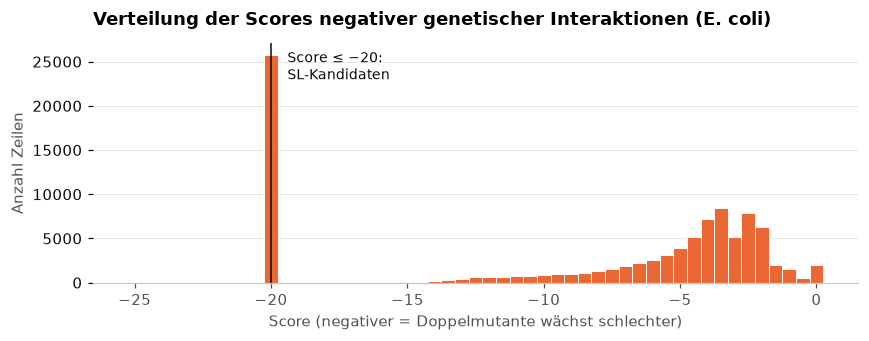

,Zeilen,stärkster Score,Median,schwächster Score
author,,,,
Babu M (2011),47678,-23.42,-20.00,-2.00
Babu M (2014),24960,-30.92,-4.73,-3.39
Gagarinova A (2016),2668,-1.02,-0.16,-0.10
Gagarinova A (2022),8121,-20.00,-1.97,-0.93
Kumar A (2016),14159,-20.25,-2.90,-2.00


In [13]:
eneg = eco_in[eco_in.type == "negative genetic interaction"].copy()
eneg["pair"] = pair_key(eneg.symA, eneg.symB)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(eneg.score.clip(lower=-25), bins=np.arange(-25.25, 0.75, 0.5), color=COLOR["E. coli K-12"], edgecolor="white", linewidth=0.6)
ax.axvline(-20, color="#0b0b0b", linewidth=1)
ax.text(-19.4, ax.get_ylim()[1] * 0.85, "Score ≤ −20:\nSL-Kandidaten", fontsize=9, color="#0b0b0b")
ax.set_title("Verteilung der Scores negativer genetischer Interaktionen (E. coli)")
ax.set_xlabel("Score (negativer = Doppelmutante wächst schlechter)")
ax.set_ylabel("Anzahl Zeilen")
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

q = eneg.groupby("author").score.describe(percentiles=[.5])[["count", "min", "50%", "max"]]
q.columns = ["Zeilen", "stärkster Score", "Median", "schwächster Score"]
q["Zeilen"] = q["Zeilen"].astype(int)
q.round(2)

* Der große Balken bei **−20** kommt vor allem aus Babu et al. (2011): Dort ist der Score bei −20 **gedeckelt**, d.h. der Effekt war so stark, wie es die Methode überhaupt messen kann.
  Das entspricht praktisch **„Doppelmutante wächst (fast) nicht“** → das sind die besten **SL-Kandidaten**.
* Die Studien verwenden **unterschiedliche Skalen** (Gagarinova 2016 liegt z.B. nur zwischen −1 und 0). Ein fester Schwellenwert ist also ein Kompromiss.

**Unsere Definition:** *E. coli*-SL-Kandidat = negative genetische Interaktion mit **Score ≤ −20**. Wie viele Paare das je nach Schwelle sind:

In [14]:
pair_best = eneg.groupby("pair").agg(score=("score", "min"), symA=("symA", "first"), symB=("symB", "first"),
                                     Studie=("author", "first"))
rows = []
for t in [-2, -3, -5, -10, -20]:
    sub = pair_best[pair_best.score <= t]
    rows.append({"Schwelle": f"Score ≤ {t}", "Genpaare": len(sub),
                 "Gene": pd.concat([sub.symA, sub.symB]).nunique()})
display(pd.DataFrame(rows).set_index("Schwelle").map(de))

ecand = pair_best[pair_best.score <= -20].copy()
ecand.sort_values("score").to_csv(OUT / "ecoli_sl_kandidaten.csv")
print("Gene im E. coli-Genom insgesamt (in diesen Daten):", de(pd.concat([eco_in.symA, eco_in.symB]).nunique()))

,Genpaare,Gene
Schwelle,,
Score ≤ -2,90.331,3.939
Score ≤ -3,74.118,3.939
Score ≤ -5,49.209,3.603
Score ≤ -10,31.379,2.467
Score ≤ -20,25.813,848


Gene im E. coli-Genom insgesamt (in diesen Daten): 4.244


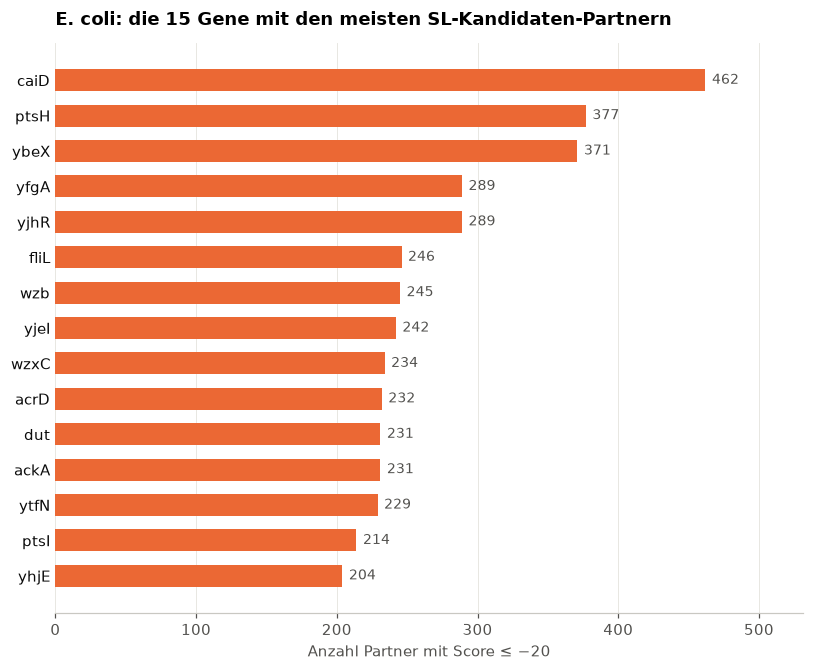

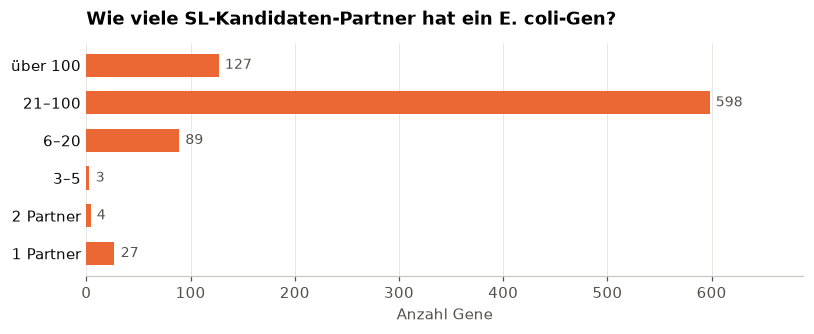

In [15]:
e_partners = (pd.concat([ecand[["symA", "symB"]].set_axis(["g", "p"], axis=1),
                         ecand[["symB", "symA"]].set_axis(["g", "p"], axis=1)])
              .groupby("g")["p"].nunique().sort_values(ascending=False))
barh(e_partners.head(15), "E. coli: die 15 Gene mit den meisten SL-Kandidaten-Partnern",
     "Anzahl Partner mit Score ≤ −20", color=COLOR["E. coli K-12"])
eb = pd.cut(e_partners, [0, 1, 2, 5, 20, 100, 10_000],
            labels=["1 Partner", "2 Partner", "3–5", "6–20", "21–100", "über 100"])
barh(eb.value_counts().sort_index().iloc[::-1], "Wie viele SL-Kandidaten-Partner hat ein E. coli-Gen?",
     "Anzahl Gene", color=COLOR["E. coli K-12"])

**Erkenntnisse *E. coli*:**
* Im Gegensatz zum Menschen wurde hier **systematisch (fast) jedes Gen mit vielen anderen kombiniert**. Das Netz ist deshalb viel **dichter** (viele Gene mit 20+ Partnern).
* Hub-Gene wie `ptsH`/`ptsI` (Zuckeraufnahme) oder `ackA` (Energiestoffwechsel) sind zentrale Stoffwechselgene. Wenn sie fehlen, ist die Zelle schon geschwächt, und jede zweite Mutation kippt sie.
* Gene mit **y-Namen** (`ybeX`, `yjhR`, …) haben noch **keine bekannte Funktion**. Auch das ist ein Ergebnis: SL-Daten helfen, Funktionen zu erraten.
* Einzige explizite SL-Zeile: `pyrD` (*E. coli*) × `URA1` (Hefe), ein Experiment, bei dem ein *E. coli*-Gen ein Hefe-Gen ersetzt. Das sagt nichts über SL *innerhalb* von *E. coli*.

## 6. Ratte: Was steckt in den Daten?

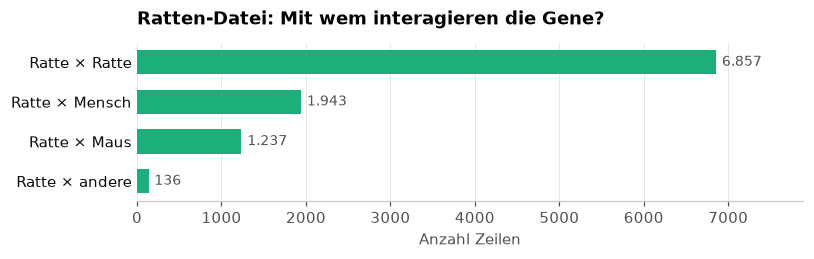

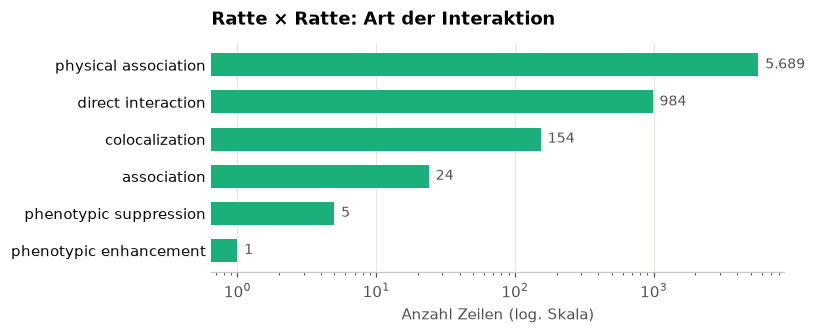

Genetische Interaktionen innerhalb der Ratte: 6
davon synthetisch letal: 0


In [16]:
r_partner = rat.assign(Partner=np.select(
    [rat.taxA.eq(10116) & rat.taxB.eq(10116), rat.taxA.eq(9606) | rat.taxB.eq(9606),
     rat.taxA.eq(10090) | rat.taxB.eq(10090)],
    ["Ratte × Ratte", "Ratte × Mensch", "Ratte × Maus"], "Ratte × andere"))
barh(r_partner.Partner.value_counts(), "Ratten-Datei: Mit wem interagieren die Gene?", "Anzahl Zeilen",
     color=COLOR["Ratte"])
barh(rat_in.type.value_counts(), "Ratte × Ratte: Art der Interaktion", "Anzahl Zeilen (log. Skala)",
     color=COLOR["Ratte"], log=True)
print("Genetische Interaktionen innerhalb der Ratte:", int(rat_in.genetisch.sum()))
print("davon synthetisch letal:", int((rat_in.type == "synthetic lethality").sum()))

**Erkenntnis Ratte:**
* Die Ratten-Daten bestehen fast nur aus **physikalischen Interaktionen** (welche Proteine aneinander binden).
* Es gibt nur eine Handvoll genetischer Interaktionen (Verstärkung/Unterdrückung eines Effekts) und **keine einzige SL**.
* **Mit unseren Daten lässt sich nicht feststellen, welche Ratten-Gene synthetisch letal sind.**
  Möglich ist nur der umgekehrte Weg: SL-Paare vom **Menschen auf die Ratte übertragen** und als Hypothese aufstellen (Abschnitt 7.2).

## 7. Wie bilden sich die Gene auf den Menschen ab?

### 7.1 Orthologie: das Werkzeug für den Vergleich

Zwei Gene in verschiedenen Spezies, die vom **selben Gen eines gemeinsamen Vorfahren** abstammen, heißen **Orthologe**.
Sie haben meist dieselbe Aufgabe. Beispiel: Das *E. coli*-Gen **recA** und das menschliche **RAD51** reparieren beide DNA-Brüche, obwohl die Namen völlig anders sind.

* **Richtig:** Orthologie über Sequenzvergleich (Datenbanken wie NCBI, OMA, Ensembl). → *liegt noch nicht im Repo, siehe Task in Abschnitt 9*.
* **Behelf (hier):** Gensymbole vergleichen (Groß-/Kleinschreibung ignorieren). Ratte `Brca1` ≈ Mensch `BRCA1`.
  Bei Säugetieren klappt das oft, weil die Namen abgestimmt sind. Bei Bakterien fast nie.

### 7.2 Ratte → Mensch (über Gensymbole)

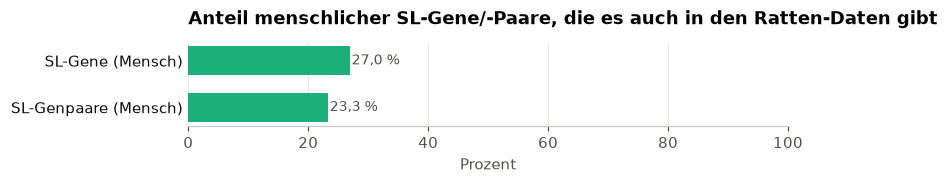


| | Anzahl |
|---|---|
| Ratten-Gene in der Datei (nur Gene mit irgendeiner Interaktion) | 3.639 |
| menschliche SL-Gene mit gleichnamigem Ratten-Gen | 527 von 1.954 |
| menschliche SL-Paare, bei denen **beide** Gene in den Ratten-Daten vorkommen | 517 von 2.219 |


,pair,symA,symB,Author
17138,CDK2 – MYC,MYC,CDK2,Zhou Z (2014)
17140,GSK3B – MYC,MYC,GSK3B,Zhou Z (2014)
17142,MYC – PHKG2,MYC,PHKG2,Zhou Z (2014)
17143,MYC – PRKCD,MYC,PRKCD,Zhou Z (2014)
17145,MYC – PRKDC,MYC,PRKDC,Zhou Z (2014)
17146,A2M – KRAS,KRAS,A2M,Luo J (2009)
17149,ACTR2 – KRAS,KRAS,ACTR2,Luo J (2009)
17151,ADAM22 – KRAS,KRAS,ADAM22,Luo J (2009)
17157,ANAPC4 – KRAS,KRAS,ANAPC4,Luo J (2009)
17158,ANXA5 – KRAS,KRAS,ANXA5,Luo J (2009)


In [17]:
human_sl_genes = set(h_genes)
rat_genes = set(rat.loc[rat.taxA == 10116, "symA"]) | set(rat.loc[rat.taxB == 10116, "symB"])
rat_upper = {g.upper() for g in rat_genes if isinstance(g, str)}

pairs_h = human_sl.drop_duplicates("pair")[["pair", "symA", "symB", "Author"]]
pairs_h["beide in Ratten-Daten"] = pairs_h.symA.str.upper().isin(rat_upper) & pairs_h.symB.str.upper().isin(rat_upper)
genes_in_rat = {g for g in human_sl_genes if g.upper() in rat_upper}

cov = pd.Series({
    "SL-Gene (Mensch)": len(genes_in_rat) / len(human_sl_genes) * 100,
    "SL-Genpaare (Mensch)": pairs_h["beide in Ratten-Daten"].mean() * 100,
})
barh(cov, "Anteil menschlicher SL-Gene/-Paare, die es auch in den Ratten-Daten gibt", "Prozent",
     color=COLOR["Ratte"], pct=True)
display(Markdown(f'''
| | Anzahl |
|---|---|
| Ratten-Gene in der Datei (nur Gene mit irgendeiner Interaktion) | {de(len(rat_genes))} |
| menschliche SL-Gene mit gleichnamigem Ratten-Gen | {de(len(genes_in_rat))} von {de(len(human_sl_genes))} |
| menschliche SL-Paare, bei denen **beide** Gene in den Ratten-Daten vorkommen | {de(pairs_h["beide in Ratten-Daten"].sum())} von {de(len(pairs_h))} |
'''))
rat_testable = pairs_h[pairs_h["beide in Ratten-Daten"]].drop(columns="beide in Ratten-Daten")
rat_testable.to_csv(OUT / "ratte_testbare_sl_paare.csv", index=False)
rat_testable.head(15)

**Wie interpretiert man das?**
* Die Ratten-Datei enthält nur ~3.600 Gene, nämlich die, für die *irgendeine* Interaktion erfasst ist. Das Ratten-Genom hat über 20.000 Gene.
  Die niedrige Abdeckung (~27 %) liegt also an **fehlenden Daten**, nicht daran, dass der Ratte diese Gene fehlen.
* Ratte und Mensch sind beide Säugetiere; für den Großteil der menschlichen Gene gibt es ein **1:1-Ortholog** in der Ratte.
* Die Liste `analysis/results/ratte_testbare_sl_paare.csv` sind **Hypothesen**: Genpaare, die beim Menschen SL sind und deren Gegenstücke in der Ratte bekannt sind.
  Ob sie in der Ratte *auch* SL sind, **sagen unsere Daten nicht**, weil es keine Ratten-SL-Messungen gibt.

### 7.3 *E. coli* → Mensch (über Gensymbole) und warum das nicht reicht

In [18]:
human_all_genes = {g.upper() for g in pd.concat([hum_in.symA, hum_in.symB]).dropna().unique()}
eco_genes = set(pd.concat([eco_in.symA, eco_in.symB]).dropna())
same_name_any = sorted(g for g in eco_genes if g.upper() in human_all_genes)
same_name_sl = sorted(g for g in eco_genes if g.upper() in human_sl_genes)
cand_genes = set(ecand.symA) | set(ecand.symB)

# Einordnung aus Lehrbuchwissen (NICHT aus den Daten) – zeigt, warum Namensgleichheit nichts beweist
NOTE = {
    "ada":  ("Zufall", "E. coli: DNA-Reparatur (Methyltransferase); Mensch ADA: Adenosin-Desaminase. Echtes Gegenstück wäre MGMT"),
    "adk":  ("Zufall", "E. coli: Adenylatkinase; Mensch ADK: Adenosinkinase (andere Reaktion)"),
    "polB": ("Zufall", "E. coli: DNA-Polymerase II; Mensch POLB: Polymerase β (andere Familie)"),
    "pth":  ("Zufall", "E. coli: Peptidyl-tRNA-Hydrolase; Mensch PTH: Parathormon"),
    "mak":  ("Zufall", "E. coli: Zucker-Kinase; Mensch MAK: Proteinkinase in Keimzellen"),
    "napG": ("Zufall", "E. coli: Nitrat-Reduktase-Untereinheit; Mensch NAPG: Vesikeltransport"),
    "cybB": ("Zufall", "E. coli: Cytochrom b561; Mensch CYBB: NADPH-Oxidase NOX2"),
    "ppiC": ("Zufall", "E. coli: Parvulin; Mensch PPIC: Cyclophilin (andere Proteinfamilie)"),
    "clpX": ("echt", "beide: Untereinheit der Clp-Protease (beim Menschen in den Mitochondrien)"),
    "hscB": ("echt", "beide: Co-Chaperon für Eisen-Schwefel-Cluster"),
    "rpe":  ("echt", "beide: Ribulose-5-phosphat-Epimerase (Zuckerstoffwechsel)"),
    "xylB": ("echt", "beide: Xylulokinase"),
    "ppiA": ("verwandt", "beide Cyclophiline (gleiche Proteinfamilie)"),
    "ppiB": ("verwandt", "beide Cyclophiline (gleiche Proteinfamilie)"),
}
tab = pd.DataFrame({"E. coli-Gen": same_name_sl,
                    "Mensch-Gen": [g.upper() for g in same_name_sl],
                    "E. coli SL-Kandidat?": ["ja" if g in cand_genes else "nein" for g in same_name_sl]})
tab["Orthologe? (Lehrbuchwissen)"] = [NOTE.get(g, ("unklar", ""))[0] for g in same_name_sl]
tab["Erklärung"] = [NOTE.get(g, ("", "ohne Orthologie-Daten nicht prüfbar"))[1] for g in same_name_sl]

display(Markdown(f'''
* *E. coli*-Gene in den Daten: **{de(len(eco_genes))}**
* davon mit **gleichem Namen** wie irgendein menschliches Gen: **{de(len(same_name_any))}** ({de(len(same_name_any)/len(eco_genes)*100, 1)} %)
* davon gleichnamig mit einem **menschlichen SL-Gen**: **{len(same_name_sl)}**
'''))
tab.to_csv(OUT / "ecoli_mensch_namensgleiche_gene.csv", index=False)
tab


* *E. coli*-Gene in den Daten: **4.244**
* davon mit **gleichem Namen** wie irgendein menschliches Gen: **108** (2,5 %)
* davon gleichnamig mit einem **menschlichen SL-Gen**: **15**


,E. coli-Gen,Mensch-Gen,E. coli SL-Kandidat?,Orthologe? (Lehrbuchwissen),Erklärung
0,ada,ADA,nein,Zufall,E. coli: DNA-Reparatur (Methyltransferase); Mensch ADA: Adenosin-Desaminase....
1,adk,ADK,nein,Zufall,E. coli: Adenylatkinase; Mensch ADK: Adenosinkinase (andere Reaktion)
2,chiA,CHIA,ja,unklar,ohne Orthologie-Daten nicht prüfbar
3,clpX,CLPX,nein,echt,beide: Untereinheit der Clp-Protease (beim Menschen in den Mitochondrien)
4,cybB,CYBB,nein,Zufall,E. coli: Cytochrom b561; Mensch CYBB: NADPH-Oxidase NOX2
5,hscB,HSCB,nein,echt,beide: Co-Chaperon für Eisen-Schwefel-Cluster
6,mak,MAK,nein,Zufall,E. coli: Zucker-Kinase; Mensch MAK: Proteinkinase in Keimzellen
7,napG,NAPG,nein,Zufall,E. coli: Nitrat-Reduktase-Untereinheit; Mensch NAPG: Vesikeltransport
8,polB,POLB,nein,Zufall,E. coli: DNA-Polymerase II; Mensch POLB: Polymerase β (andere Familie)
9,ppiA,PPIA,nein,verwandt,beide Cyclophiline (gleiche Proteinfamilie)


In [19]:
# Gibt es ein E. coli-SL-Kandidatenpaar, dessen gleichnamige Gene auch beim Menschen ein SL-Paar bilden?
human_pairs_upper = set(pair_key(human_sl.symA.str.upper(), human_sl.symB.str.upper()))
ecand_upper = pair_key(ecand.symA.str.upper(), ecand.symB.str.upper())
conserved = sorted(set(ecand_upper) & human_pairs_upper)
print("E. coli-SL-Kandidatenpaare, die (per Name) auch beim Menschen SL sind:", len(conserved), conserved)

E. coli-SL-Kandidatenpaare, die (per Name) auch beim Menschen SL sind: 0 []


**Fazit zur Abbildung *E. coli* → Mensch:**
* Nur etwa 2–3 % der *E. coli*-Gene haben überhaupt einen gleichnamigen menschlichen Partner. Von den 15, die zu einem menschlichen SL-Gen passen, sind **9 reiner Zufall** (gleiche Abkürzung, völlig anderes Protein, z.B. `ada` ≠ `ADA`, `pth` ≠ `PTH`).
* Umgekehrt haben echte Orthologe meist **verschiedene Namen** (`recA` ↔ `RAD51`, `mutS` ↔ `MSH2`, `mutL` ↔ `MLH1`). Über Namen findet man sie nie.
* Per Name wird **kein einziges** SL-Paar zwischen *E. coli* und Mensch gefunden. Das heißt **nicht**, dass es keine gibt, sondern dass die **Methode (Namensvergleich) ungeeignet** ist.
* → Für *E. coli* braucht es zwingend echte Orthologie-Daten (Task in Abschnitt 9).

## 8. Ist synthetische Letalität auf den Menschen übertragbar? Und wie?

### 8.1 Wann ist ein SL-Paar übertragbar?

Ein SL-Paar (Gen A + Gen B) aus Spezies X gilt nur dann auch beim Menschen, wenn **alle** Bedingungen erfüllt sind:

1. **Beide Gene haben ein menschliches Ortholog**, am besten 1:1 (nicht ein Gen ↔ mehrere Kopien, denn Kopien können sich gegenseitig ersetzen).
2. **Die Aufgabe ist dieselbe**: Beide Gene sind beim Menschen Teil desselben Stoffwechsel-/Reparaturwegs.
3. **Die „Ersatzbrücke“ ist dieselbe**: Beim Menschen darf es keinen *dritten* Weg geben, der den Ausfall abfängt. Genau das unterscheidet Spezies am häufigsten.
4. **Keines der beiden Gene ist beim Menschen allein schon lebenswichtig**, sonst ist es nicht *synthetisch* letal, sondern einfach letal.
5. **Der Zellkontext passt**: Beim Menschen hängt SL stark von der Zelllinie ab (Abschnitt 4.4).

### 8.2 Bewertung pro Spezies

| | **Ratte → Mensch** | ***E. coli* → Mensch** |
|---|---|---|
| Verwandtschaft | sehr nah (beide Säugetiere) | extrem entfernt (Bakterium vs. Mensch, über 3 Mrd. Jahre getrennt) |
| Gene mit menschlichem Ortholog | großer Teil, meist 1:1 | nur ein kleiner Teil (Kernprozesse) |
| SL-Daten in unserem Datensatz | **keine** | ~25.800 SL-Kandidaten (Score ≤ −20) |
| Übertragbarkeit | **hoch plausibel, aber mit unseren Daten unbelegt** | **gering**, nur für hoch konservierte Prozesse |
| Wo sinnvoll? | fast alle Signalwege, Krebsgene; Ratte als Tiermodell zum Testen von Mensch-Hypothesen | DNA-Reparatur, DNA-Replikation, Nukleotid-/Grundstoffwechsel, Protein-Qualitätskontrolle |
| Wo **nie** übertragbar? | wenige artspezifische Gene | alles Bakterienspezifische: Zellwand, Geißel, Zucker-Transportsysteme (z.B. `ptsH`), Großteil der y-Gene |
| Richtung in der Praxis | meist **Mensch → Ratte** (Hypothese im Tier prüfen) | **E. coli → Mensch** nur als Ideengeber |

### 8.3 Wie überträgt man SL konkret? (Arbeitsablauf)

1. **SL-Paar in Spezies X finden**: z.B. *E. coli*-Paar mit Score ≤ −20 (`analysis/results/ecoli_sl_kandidaten.csv`).
2. **Orthologe suchen**: Für Gen A und Gen B das menschliche Ortholog nachschlagen (NCBI / OMA). Paare ohne Ortholog fallen weg.
3. **Prüfen, ob schon bekannt**: Ist das menschliche Paar bereits in der Mensch-SL-Liste? → dann ist SL **über Spezies hinweg bestätigt (konserviert)**.
4. **Lebenswichtigkeit prüfen**: Ist eines der beiden menschlichen Gene allein schon essentiell? → verwerfen.
5. **Im Labor testen**: Beide Gene in einer menschlichen Zelllinie ausschalten (CRISPR) und schauen, ob die Zellen sterben.

Genau so hat z.B. **Srivas et al. (2016)**, eine der großen Studien in unserem Mensch-Datensatz (siehe Abschnitt 4.2), gearbeitet:
SL-Paare aus Hefe wurden über Orthologe auf den Menschen übertragen und in HeLa-Zellen getestet. Nur ein Teil davon bestätigte sich beim Menschen.

In [20]:
# Wie viele E. coli-SL-Kandidaten könnten überhaupt in Frage kommen (beide Gene mit gleichnamigem Mensch-Gen)?
both_named = ecand[ecand.symA.str.upper().isin(human_all_genes) & ecand.symB.str.upper().isin(human_all_genes)]
display(Markdown(f'''
**Trichter: *E. coli*-SL-Kandidaten → Mensch (Behelf über Gensymbole)**

| Stufe | Genpaare |
|---|---|
| 1. *E. coli* SL-Kandidatenpaare (Score ≤ −20) | **{de(len(ecand))}** |
| 2. … beide Gene haben ein gleichnamiges Mensch-Gen | **{de(len(both_named))}** |
| 3. … davon auch beim Menschen als SL bekannt | **{de(len(conserved))}** |
'''))
both_named.sort_values("score").head(10)


**Trichter: *E. coli*-SL-Kandidaten → Mensch (Behelf über Gensymbole)**

| Stufe | Genpaare |
|---|---|
| 1. *E. coli* SL-Kandidatenpaare (Score ≤ −20) | **25.813** |
| 2. … beide Gene haben ein gleichnamiges Mensch-Gen | **9** |
| 3. … davon auch beim Menschen als SL bekannt | **0** |


,score,symA,symB,Studie
pair,,,,
acpP – dut,-20.0,acpP,dut,Babu M (2011)
acpT – dut,-20.0,acpT,dut,Babu M (2011)
chiA – dgkA,-20.0,chiA,dgkA,Babu M (2011)
chiA – mpl,-20.0,chiA,mpl,Babu M (2011)
dut – ispD,-20.0,dut,ispD,Babu M (2011)
dut – purB,-20.0,dut,purB,Babu M (2011)
fadD – lpp,-20.0,lpp,fadD,Babu M (2011)
galE – lpp,-20.0,galE,lpp,Babu M (2011)
galT – ttk,-20.0,galT,ttk,Babu M (2011)


Der Trichter zeigt: Von ~25.800 Kandidaten bleiben per Namensvergleich nur sehr wenige übrig, und davon ist **keins** als menschliches SL-Paar bekannt.
In der Liste stehen Paare mit echten Orthologen (z.B. `dut` ↔ *DUT*, `galE` ↔ *GALE*) direkt neben Zufallstreffern (`lpp` ist ein Bakterien-Zellwandprotein, *LPP* beim Menschen etwas ganz anderes).
Mit echten Orthologie-Daten wird Stufe 2 deutlich breiter (viele echte Orthologe haben andere Namen), und erst dann ist Stufe 3 aussagekräftig.

---

## 9. Fazit

**1. Wie stelle ich fest, ob und welche Gene SL sind?**
* SL-Datei nach `Organism ID` filtern bzw. in der MITAB-Datei nach `Interaction Types = MI:2370` (explizit) oder `MI:2373` + Score (Kandidaten).
* Nur Zeilen mit **beiden Genen aus derselben Spezies** zählen.

**2. Wie sind die SL-Gene pro Spezies verteilt?**
* **Mensch:** ~2.250 SL-Zeilen, ~2.200 Genpaare, ~1.950 Gene. Wenige Hub-Gene (KRAS, CSK, FBXW7, ATR, TP53), die meisten Gene haben nur 1 Partner.
  Gemessen fast ausschließlich in **Krebszelllinien** (T47D, HeLa, DLD-1, HCT116, …); fast jedes Paar nur **einmal** belegt.
* ***E. coli*:** keine expliziten SL, aber ~97.000 negative genetische Interaktionen; ~25.800 starke (Score ≤ −20) **SL-Kandidaten**
  bei ~850 Genen, systematisch gemessen → dichtes Netz.
* **Ratte:** **keine SL-Daten**; mit dem vorhandenen Material nicht bestimmbar.

**3. Übertragbarkeit auf den Menschen**
* **Ratte:** biologisch gut übertragbar (nahe Verwandtschaft, meist 1:1-Orthologe), aber es gibt keine Ratten-SL zum Übertragen.
  Sinnvoll ist der umgekehrte Weg (517 Mensch-SL-Paare, deren Gene auch in den Ratten-Daten vorkommen).
* ***E. coli*:** nur für konservierte Kernprozesse; der Großteil ist bakterienspezifisch. Mit Namensvergleich nicht prüfbar, dafür sind Orthologie-Daten nötig.
* Generell: SL ist **kontextabhängig** (schon zwischen menschlichen Zelllinien). Übertragung liefert **Hypothesen**, die im Labor bestätigt werden müssen.

### Offene Tasks
* [ ] **Orthologie-Daten ergänzen** (in `install.sh`, nicht committen):
  NCBI `gene_orthologs.gz` für Ratte ↔ Mensch, OMA-Paare (oder eggNOG) für *E. coli* ↔ Mensch.
  Danach Abschnitt 7/8 mit echten Orthologen statt Gensymbolen neu rechnen. *(siehe `TODO.md`)*
* [ ] Optional: Gen-Essentialität beim Menschen (z.B. DepMap) ergänzen, um Schritt 4 des Arbeitsablaufs automatisch zu prüfen.
* [ ] Optional: SL-Datei und Organismus-Dateien auf **dieselbe BioGRID-Version** bringen.

Alle Ergebnistabellen liegen in `analysis/results/`.

---
*Technischer Anhang:* Die folgende Zelle speichert die Kennzahlen als `results/report_data.json`. Daraus wird der HTML-Bericht erzeugt, damit Bericht und Notebook dieselben Zahlen zeigen.

In [21]:
import json
hist_edges = np.arange(-25.25, 0.75, 0.5)
hist_vals, _ = np.histogram(eneg.score.clip(lower=-25), bins=hist_edges)
S = lambda s: [[str(k), int(v)] for k, v in s.items()]
report = {
    "sl_file": SL_FILE.name,
    "overview": {k: {c: int(v) for c, v in row.items()} for k, row in ov.iterrows()},
    "org_counts": S(org_counts),
    "human": {
        "rows": len(human_sl), "pairs": int(human_sl.pair.nunique()), "genes": int(h_genes.nunique()),
        "studies": int(human_sl.Author.nunique()), "pairs_multi": int((pair_n > 1).sum()),
        "ht_pct": float(human_sl.Throughput.str.contains("High").mean() * 100),
        "degree_bins": S(bins.value_counts().sort_index()), "top_genes": S(partners.head(12)),
        "methods": S(m), "studies_top": S(human_sl.Author.value_counts().head(8)),
        "cell_lines": [[i, r["Gewebe / Herkunft"], int(r["SL-Zeilen"]), int(r["Genpaare"]), r["Köder-Gen(e)"], int(r["Studien"])]
                       for i, r in cl_tab.iterrows()],
        "pairs_multi_study_pct": float((per_pair.Studien > 1).mean() * 100),
        "pairs_multi_cellline": int((per_pair.Zelllinien > 1).sum()),
        "old_file_sl": int((hum_in.type == "synthetic lethality").sum()),
    },
    "ecoli": {
        "genes": int(pd.concat([eco_in.symA, eco_in.symB]).nunique()),
        "hist": {"edges": [float(x) for x in hist_edges], "counts": [int(x) for x in hist_vals]},
        "thresholds": rows, "cand_pairs": len(ecand),
        "cand_genes": int(pd.concat([ecand.symA, ecand.symB]).nunique()),
        "top_genes": S(e_partners.head(12)), "degree_bins": S(eb.value_counts().sort_index()),
        "studies": [[a, int(r["Zeilen"]), float(r["stärkster Score"]), float(r["Median"]), float(r["schwächster Score"])]
                    for a, r in q.iterrows()],
    },
    "rat": {
        "partners": S(r_partner.Partner.value_counts()), "types": S(rat_in.type.value_counts()),
        "genes": len(rat_genes), "sl_genes_in_rat": len(genes_in_rat), "human_sl_genes": len(human_sl_genes),
        "pairs_in_rat": int(pairs_h["beide in Ratten-Daten"].sum()), "human_pairs": len(pairs_h),
    },
    "mapping": {
        "ecoli_same_name_any": len(same_name_any), "ecoli_same_name_sl": len(same_name_sl),
        "name_table": tab.values.tolist(), "both_named": len(both_named), "conserved": len(conserved),
        "both_named_list": both_named.sort_values("score")[["symA", "symB", "score"]].values.tolist(),
    },
}
(OUT / "report_data.json").write_text(json.dumps(report, ensure_ascii=False, indent=1))
print("gespeichert:", OUT / "report_data.json")

gespeichert: /Users/nico/4bhif/synlet-dbi4/analysis/results/report_data.json
